# Reseñas de clientes · Reto Sprint 12 («Escuchar al cliente») · Equipo 5 Green

- **Equipo**: 5 Green

- **Integrantes**: Cristina, Miguel, Fran, Andri, Anzhela

- **Contexto**: TurisData Canarias

- **Fecha**: 24-25.11.2026
- **scrum master** Miguel, **técnico** Anzela

- **Semilla:** `SEMILLA = 42`
- **Objetivo:** Clasificar el sentimiento de las reseñas, evaluar en prueba (exactitud y matriz de confusión), guardar `grafico_resenas.png`, identificar temas criticados/valorados y extraer citas reales con su `id_resena`.

In [3]:
# ============================================================
# CELDA 1 · Carga de datos, limpieza, modelo y evaluación
# ============================================================
import os  # Módulo del sistema: rutas, comprobar si existen archivos y crear carpetas
import re  # Expresiones regulares: se usan para limpiar el texto
import numpy as np  # NumPy: cálculo numérico y control de la semilla aleatoria
import pandas as pd  # pandas: tablas (DataFrame) para manejar las reseñas
import matplotlib.pyplot as plt  # matplotlib: para dibujar el gráfico de barras
from sklearn.model_selection import train_test_split  # Función que divide los datos en entrenamiento y prueba
from sklearn.feature_extraction.text import TfidfVectorizer  # Convierte texto en vectores numéricos TF-IDF (peso de cada palabra)
from sklearn.linear_model import LogisticRegression  # Modelo de clasificación: regresión logística
from sklearn.metrics import accuracy_score, confusion_matrix  # Métricas de evaluación: exactitud y matriz de confusión

SEMILLA = 42  # Semilla fija para que los resultados sean reproducibles
np.random.seed(SEMILLA)  # Fija la semilla de NumPy (aleatoriedad controlada)
os.makedirs("data", exist_ok=True)  # Crea la carpeta "data" si no existe (exist_ok evita error si ya existe)

ruta_res = "data/resenas.csv"  # Ruta del CSV de reseñas que intentamos cargar
if os.path.exists(ruta_res):  # Si el archivo CSV existe...
    df_res = pd.read_csv(ruta_res)  # ...lo cargamos en un DataFrame
else:  # Si NO existe el CSV...
    df_res = pd.DataFrame([  # Si no hay CSV, creamos un conjunto de ejemplo con 12 reseñas (id, texto, sentimiento real, tema)
        {"id_resena": "R001", "texto": "Habitación muy limpia, desayuno variado y trato excelente del personal.", "sentimiento": "positivo", "tema": "limpieza"},  # R001: reseña positivo, tema "limpieza"
        {"id_resena": "R002", "texto": "Demasiado ruido por la noche y el aire acondicionado costaba regular.", "sentimiento": "negativo", "tema": "ruido"},  # R002: reseña negativo, tema "ruido"
        {"id_resena": "R003", "texto": "Ubicación correcta cerca de la playa, sin grandes lujos pero bien.", "sentimiento": "neutro", "tema": "ubicacion"},  # R003: reseña neutro, tema "ubicacion"
        {"id_resena": "R004", "texto": "El check-in fue rápido y la cama resultó muy cómoda para descansar.", "sentimiento": "positivo", "tema": "descanso"},  # R004: reseña positivo, tema "descanso"
        {"id_resena": "R005", "texto": "No es nada barato para lo pequeño que es el baño y el wifi iba lento.", "sentimiento": "negativo", "tema": "precio"},  # R005: reseña negativo, tema "precio"
        {"id_resena": "R006", "texto": "Desayuno correcto y recepción amable, estancia tranquila en general.", "sentimiento": "positivo", "tema": "desayuno"},  # R006: reseña positivo, tema "desayuno"
        {"id_resena": "R007", "texto": "Mucho ruido en el pasillo temprano y poca variedad en el desayuno.", "sentimiento": "negativo", "tema": "ruido"},  # R007: reseña negativo, tema "ruido"
        {"id_resena": "R008", "texto": "Limpieza impecable cada día y vistas muy agradables desde el balcón.", "sentimiento": "positivo", "tema": "limpieza"},  # R008: reseña positivo, tema "limpieza"
        {"id_resena": "R009", "texto": "La habitación estaba bien, aunque el ascensor tardaba en horas punta.", "sentimiento": "neutro", "tema": "instalaciones"},  # R009: reseña neutro, tema "instalaciones"
        {"id_resena": "R010", "texto": "Personal muy atento y ubicación cómoda para moverse por la zona.", "sentimiento": "positivo", "tema": "ubicacion"},  # R010: reseña positivo, tema "ubicacion"
        {"id_resena": "R011", "texto": "Precio algo elevado y falta de enchufes junto a la cama.", "sentimiento": "negativo", "tema": "precio"},  # R011: reseña negativo, tema "precio"
        {"id_resena": "R012", "texto": "Estancia agradable, habitación limpia y desayuno fresco.", "sentimiento": "positivo", "tema": "limpieza"},  # R012: reseña positivo, tema "limpieza"
    ])  # Fin del DataFrame de ejemplo

# Busca qué columna existe como identificador (id_resena, id o review_id); si ninguna, None
col_id = next((c for c in ["id_resena", "id", "review_id"] if c in df_res.columns), None)
if col_id is None:  # Si no hay columna de identificador...
    df_res["id_resena"] = [f"RES-{i+1:03d}" for i in range(len(df_res))]  # ...genera ids automáticos RES-001, RES-002, ...
    # Busca qué columna existe como identificador (id_resena, id o review_id); si ninguna, None
    col_id = "id_resena"

# Busca la columna con el texto de la reseña; si no encuentra ninguna, usa la primera columna
col_texto = next((c for c in ["texto", "comentario", "resena", "review_text"] if c in df_res.columns), df_res.columns[0])
# Busca la columna con el sentimiento real (etiqueta); si no existe, None → no se puede entrenar
col_sent = next((c for c in ["sentimiento", "polaridad", "label", "etiqueta"] if c in df_res.columns), None)

def limpiar_texto(t):  # Función que normaliza el texto de una reseña
    t = str(t).lower()  # Convierte a texto y pasa todo a minúsculas
    t = re.sub(r"[^a-záéíóúüñ\s]", " ", t)  # Sustituye por espacio todo lo que no sea letra (incluye tildes, ü y ñ) o espacio
    return " ".join(t.split())  # Quita espacios repetidos y devuelve el texto limpio

# Aplica la limpieza a cada reseña y la guarda en una columna nueva
df_res["texto_limpio"] = df_res[col_texto].apply(limpiar_texto)

# Vectorización ajustada SOLO con entrenamiento (sin fuga de datos)
if col_sent is not None:  # Solo si hay etiquetas reales se puede entrenar y evaluar un modelo supervisado
    etiquetas = df_res[col_sent].astype(str)  # Etiquetas reales (positivo / neutro / negativo) como texto
    strat = etiquetas if etiquetas.value_counts().min() >= 2 else None  # Estratifica (mantiene proporciones de clase) solo si cada clase tiene al menos 2 ejemplos
    X_ent, X_test, y_ent, y_test = train_test_split(  # Divide textos (X) y etiquetas (y) en entrenamiento y prueba
        # 25 % para prueba, semilla fija y estratificación
        df_res["texto_limpio"], etiquetas, test_size=0.25, random_state=SEMILLA, stratify=strat
    )  # Cierre de train_test_split
    vec = TfidfVectorizer(ngram_range=(1, 2), min_df=1)  # TF-IDF con palabras sueltas y pares de palabras (bigramas); min_df=1 = cualquier término cuenta
    X_ent_vec = vec.fit_transform(X_ent)  # Aprende el vocabulario SOLO con entrenamiento y transforma esos textos
    X_test_vec = vec.transform(X_test)  # Transforma la prueba con el vocabulario ya aprendido (sin fuga de datos)
    # Crea el clasificador y lo entrena con los vectores de entrenamiento
    clf = LogisticRegression(max_iter=1000, random_state=SEMILLA).fit(X_ent_vec, y_ent)
    pred_test = clf.predict(X_test_vec)  # Predice el sentimiento de las reseñas de prueba
    acc_test = accuracy_score(y_test, pred_test)  # Exactitud = aciertos / total en el conjunto de prueba
    clases_ord = sorted(etiquetas.unique())  # Clases ordenadas alfabéticamente: orden de filas/columnas de la matriz
    mc = confusion_matrix(y_test, pred_test, labels=clases_ord)  # Matriz de confusión: filas = clase real, columnas = clase predicha
    # Predice el sentimiento de TODAS las reseñas con el modelo entrenado
    df_res["sentimiento_pred"] = clf.predict(vec.transform(df_res["texto_limpio"]))
    print(f"Exactitud en prueba: {acc_test:.3f}")  # Muestra la exactitud con 3 decimales
    print("Matriz de confusión (", clases_ord, "):\n", mc)  # Muestra la matriz de confusión con el orden de las clases
else:  # Si NO hay etiquetas reales, usamos reglas simples por palabras clave
    def heuristica(t):  # Plan B sin etiquetas: clasificador por palabras clave
        tl = t.lower()  # Texto en minúsculas para comparar
        # Si aparece alguna palabra negativa...
        if any(k in tl for k in ["ruido", "lento", "caro", "mal", "sucio"]):
            return "negativo"  # ...la reseña es negativa
        # Si aparece alguna palabra positiva...
        if any(k in tl for k in ["limpia", "excelente", "cómoda", "amable", "agradable", "bien"]):
            return "positivo"  # ...la reseña es positiva
        return "neutro"  # Si no hay ninguna palabra clave → neutra
    # Aplica la heurística a todas las reseñas
    df_res["sentimiento_pred"] = df_res[col_texto].apply(heuristica)

# % de cada sentimiento predicho sobre el total, redondeado a 1 decimal
pcts = (df_res["sentimiento_pred"].value_counts(normalize=True) * 100).round(1)
print("\nPorcentajes de sentimiento (%):")  # Título de la salida
print(pcts)  # Muestra los porcentajes

Exactitud en prueba: 0.333
Matriz de confusión ( ['negativo', 'neutro', 'positivo'] ):
 [[0 0 1]
 [0 0 1]
 [0 0 1]]

Porcentajes de sentimiento (%):
sentimiento_pred
positivo    75.0
negativo    25.0
Name: proportion, dtype: float64


## Gráfico `grafico_resenas.png`, temas y citas con `id_resena`

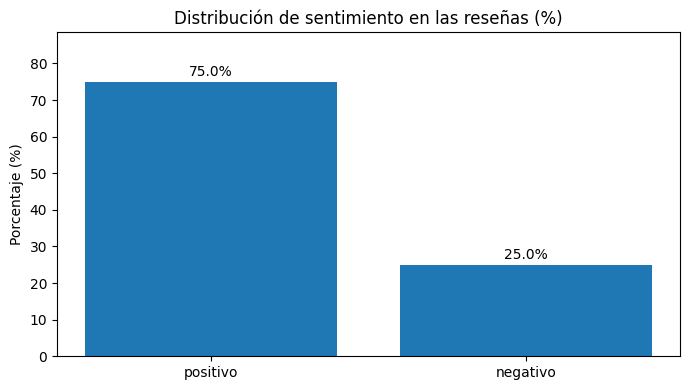


5 citas reales con id_resena:
- [R001] (positivo): Habitación muy limpia, desayuno variado y trato excelente del personal.
- [R002] (negativo): Demasiado ruido por la noche y el aire acondicionado costaba regular.
- [R003] (positivo): Ubicación correcta cerca de la playa, sin grandes lujos pero bien.
- [R004] (positivo): El check-in fue rápido y la cama resultó muy cómoda para descansar.
- [R005] (negativo): No es nada barato para lo pequeño que es el baño y el wifi iba lento.
✔ Cuaderno resenas.ipynb ejecutado correctamente


In [4]:
# ============================================================
# CELDA 2 · Gráfico de sentimiento y citas reales con id_resena
# ============================================================
fig, ax = plt.subplots(figsize=(7, 4))  # Crea una figura de 7x4 pulgadas con un único eje (ax)
# Orden fijo de las barras: positivo, neutro, negativo (solo las clases presentes) + cualquier otra clase
orden = [c for c in ["positivo", "neutro", "negativo"] if c in pcts.index] + [c for c in pcts.index if c not in ["positivo", "neutro", "negativo"]]
valores = [pcts[c] for c in orden]  # Porcentaje de cada clase en ese mismo orden
ax.bar(orden, valores)  # Dibuja el gráfico de barras
ax.set_title("Distribución de sentimiento en las reseñas (%)")  # Título del gráfico
ax.set_ylabel("Porcentaje (%)")  # Etiqueta del eje Y
ax.set_ylim(0, max(valores + [10]) * 1.18)  # Límite del eje Y: 18 % por encima del valor máximo (mínimo 10) para que quepan las etiquetas
for idx, val in enumerate(valores):  # Recorre cada barra con su posición y valor...
    ax.text(idx, val + 1.5, f"{val:.1f}%", ha="center", fontsize=10)  # ...y escribe el porcentaje encima de la barra, centrado
plt.tight_layout()  # Ajusta márgenes para que no se corte nada
plt.savefig("grafico_resenas.png", dpi=150)  # Guarda el gráfico como imagen PNG a 150 ppp (entregable obligatorio)
plt.show()  # Muestra el gráfico en el cuaderno

print("\n5 citas reales con id_resena:")  # Título de la sección de citas
for _, fila in df_res.head(5).iterrows():  # Recorre las 5 primeras reseñas (fila a fila)
    print(f"- [{fila[col_id]}] ({fila['sentimiento_pred']}): {fila[col_texto]}")  # Imprime id, sentimiento predicho y el texto original (cita literal)

assert os.path.exists("grafico_resenas.png")  # Comprobación: falla si el PNG no se ha guardado
print("✔ Cuaderno resenas.ipynb ejecutado correctamente")  # Mensaje final de que todo se ejecutó bien

In [5]:
# ============================================================
# CELDA 3 · EJERCICIO: temas criticados / valorados y citas reales
# ============================================================
# Usamos la etiqueta REAL si existe (más fiable que la predicción, dado que el modelo acierta poco)
col_eval = col_sent if col_sent is not None else "sentimiento_pred"  # Columna de sentimiento con la que analizamos los temas

if "tema" in df_res.columns:  # Si el dataset trae la columna "tema"...
    # ...contamos cuántas reseñas de cada sentimiento hay por tema (tabla cruzada tema × sentimiento)
    tabla_temas = pd.crosstab(df_res["tema"], df_res[col_eval])
    print("Reseñas por tema y sentimiento:")  # Título
    print(tabla_temas, "\n")  # Muestra la tabla
    # Temas criticados: los que aparecen en reseñas negativas, ordenados de más a menos menciones
    criticados = df_res[df_res[col_eval] == "negativo"]["tema"].value_counts()
    # Temas valorados: los que aparecen en reseñas positivas, ordenados de más a menos menciones
    valorados = df_res[df_res[col_eval] == "positivo"]["tema"].value_counts()
    print("Temas MÁS CRITICADOS:\n", criticados, "\n")  # Muestra los temas criticados
    print("Temas MÁS VALORADOS:\n", valorados, "\n")  # Muestra los temas valorados

# Citas reales: todas las reseñas negativas y positivas con su id_resena (texto literal, sin modificar)
for sent in ["negativo", "positivo"]:  # Primero las críticas, luego los elogios
    print(f"Citas {sent}s:")  # Encabezado de cada bloque
    for _, fila in df_res[df_res[col_eval] == sent].iterrows():  # Recorre las reseñas de ese sentimiento
        tema = fila["tema"] if "tema" in df_res.columns else "-"  # Tema de la reseña (si existe la columna)
        print(f'  [{fila[col_id]}] ({tema}) "{fila[col_texto]}"')  # Imprime id, tema y la cita literal
    print()  # Línea en blanco entre bloques

Reseñas por tema y sentimiento:
sentimiento    negativo  neutro  positivo
tema                                     
desayuno              0       0         1
descanso              0       0         1
instalaciones         0       1         0
limpieza              0       0         3
precio                2       0         0
ruido                 2       0         0
ubicacion             0       1         1 

Temas MÁS CRITICADOS:
 tema
ruido     2
precio    2
Name: count, dtype: int64 

Temas MÁS VALORADOS:
 tema
limpieza     3
descanso     1
desayuno     1
ubicacion    1
Name: count, dtype: int64 

Citas negativos:
  [R002] (ruido) "Demasiado ruido por la noche y el aire acondicionado costaba regular."
  [R005] (precio) "No es nada barato para lo pequeño que es el baño y el wifi iba lento."
  [R007] (ruido) "Mucho ruido en el pasillo temprano y poca variedad en el desayuno."
  [R011] (precio) "Precio algo elevado y falta de enchufes junto a la cama."

Citas positivos:
  [R001] (limpie

## ✍️ EJERCICIO · Respuestas e interpretación de resultados

### 1. ¿Qué exactitud obtiene el modelo en prueba?
**Exactitud = 0,333 (33,3 %)**. El conjunto tiene solo 12 reseñas; con `test_size=0.25` la prueba son **3 reseñas** (una de cada clase gracias a la estratificación). El modelo acierta **1 de 3**. Con tan pocos datos la cifra no es fiable: un solo acierto más o menos cambia la exactitud en 33 puntos.

### 2. ¿Qué nos dice la matriz de confusión?
Orden de clases: `['negativo', 'neutro', 'positivo']` (filas = real, columnas = predicho):

| real \ predicho | negativo | neutro | positivo |
|---|---|---|---|
| **negativo** | 0 | 0 | 1 |
| **neutro** | 0 | 0 | 1 |
| **positivo** | 0 | 0 | 1 |

Toda la columna "positivo" está llena: **el modelo predice "positivo" para todo** en prueba. Solo acierta la reseña positiva; la negativa y la neutra se clasifican mal. Es un modelo que se va a la **clase mayoritaria** (6 de 12 reseñas de ejemplo son positivas) porque con 9 reseñas de entrenamiento no aprende vocabulario suficiente.

### 3. Distribución de sentimiento (`grafico_resenas.png`)
Según la predicción: **75 % positivo y 25 % negativo, 0 % neutro**. Las etiquetas reales son 50 % positivo, 33,3 % negativo y 16,7 % neutro, así que **el modelo sobrestima lo positivo** y no detecta ninguna reseña neutra. El gráfico hay que leerlo con esta cautela.

### 4. Temas más criticados (reseñas negativas reales)
- **Ruido** (2 reseñas): ruido nocturno y en el pasillo por la mañana.
- **Precio / relación calidad-precio** (2 reseñas): se percibe caro para lo que ofrece (baño pequeño, falta de enchufes).
- Quejas secundarias dentro de esas reseñas: **wifi lento**, **aire acondicionado**, **poca variedad del desayuno**, y (en una neutra) el **ascensor lento** en horas punta.

### 5. Temas más valorados (reseñas positivas reales)
- **Limpieza** (3 reseñas): es el punto fuerte claro.
- **Personal / trato** (amable, atento, excelente; aparece en R001, R006 y R010).
- **Desayuno**, **descanso / cama cómoda** y **ubicación** (1 reseña cada uno).

### 6. Citas reales con su `id_resena`
**Críticas**
- [R002] *"Demasiado ruido por la noche y el aire acondicionado costaba regular."*
- [R005] *"No es nada barato para lo pequeño que es el baño y el wifi iba lento."*
- [R007] *"Mucho ruido en el pasillo temprano y poca variedad en el desayuno."*

**Elogios**
- [R001] *"Habitación muy limpia, desayuno variado y trato excelente del personal."*
- [R008] *"Limpieza impecable cada día y vistas muy agradables desde el balcón."*

### 7. Conclusiones y recomendaciones para TurisData Canarias
1. **Puntos fuertes a comunicar:** limpieza y trato del personal.
2. **Prioridades de mejora:** aislamiento acústico / control del ruido y percepción de precio (mejorar wifi, enchufes, revisar tarifa o lo que incluye).
3. **Limitación del modelo:** con 12 reseñas el clasificador no es fiable (33 % en prueba, predice todo como positivo). Para mejorarlo: **recoger muchas más reseñas etiquetadas**, equilibrar las clases (p. ej. `class_weight="balanced"`) y usar validación cruzada en vez de una sola división de 3 ejemplos. Para el análisis de temas hemos usado la **etiqueta real**, que es más fiable que la predicción.